# Computing Ext, Tor and their products

A finite encoded module gives us linear maps as well as dimensions. We can therefore ask algebraic questions that a list of ranks cannot answer: which module maps exist, which extension classes are nonzero, and what happens when two such classes compose?

This guide begins directly with a finite diagram. No point cloud is needed. If your input is an `EncodingResult`, `OP.ext` uses its finite module and base in the same way. These computations belong to the recorded finite category; recovery of an ambient persistence module by pullback does not identify its ambient Ext with these groups. See [which category is being computed](../math_categories.md).

You should be comfortable with vector spaces, linear maps, and the idea of a quotient by a subspace. We will first count classes, then select representatives, compose two degree-one classes, and examine the additional data required for Tor multiplication. [Resolutions](resolutions.ipynb) explains the finite resolutions behind the calls; the [reference](../src/reference/derived.md) specifies their contracts.

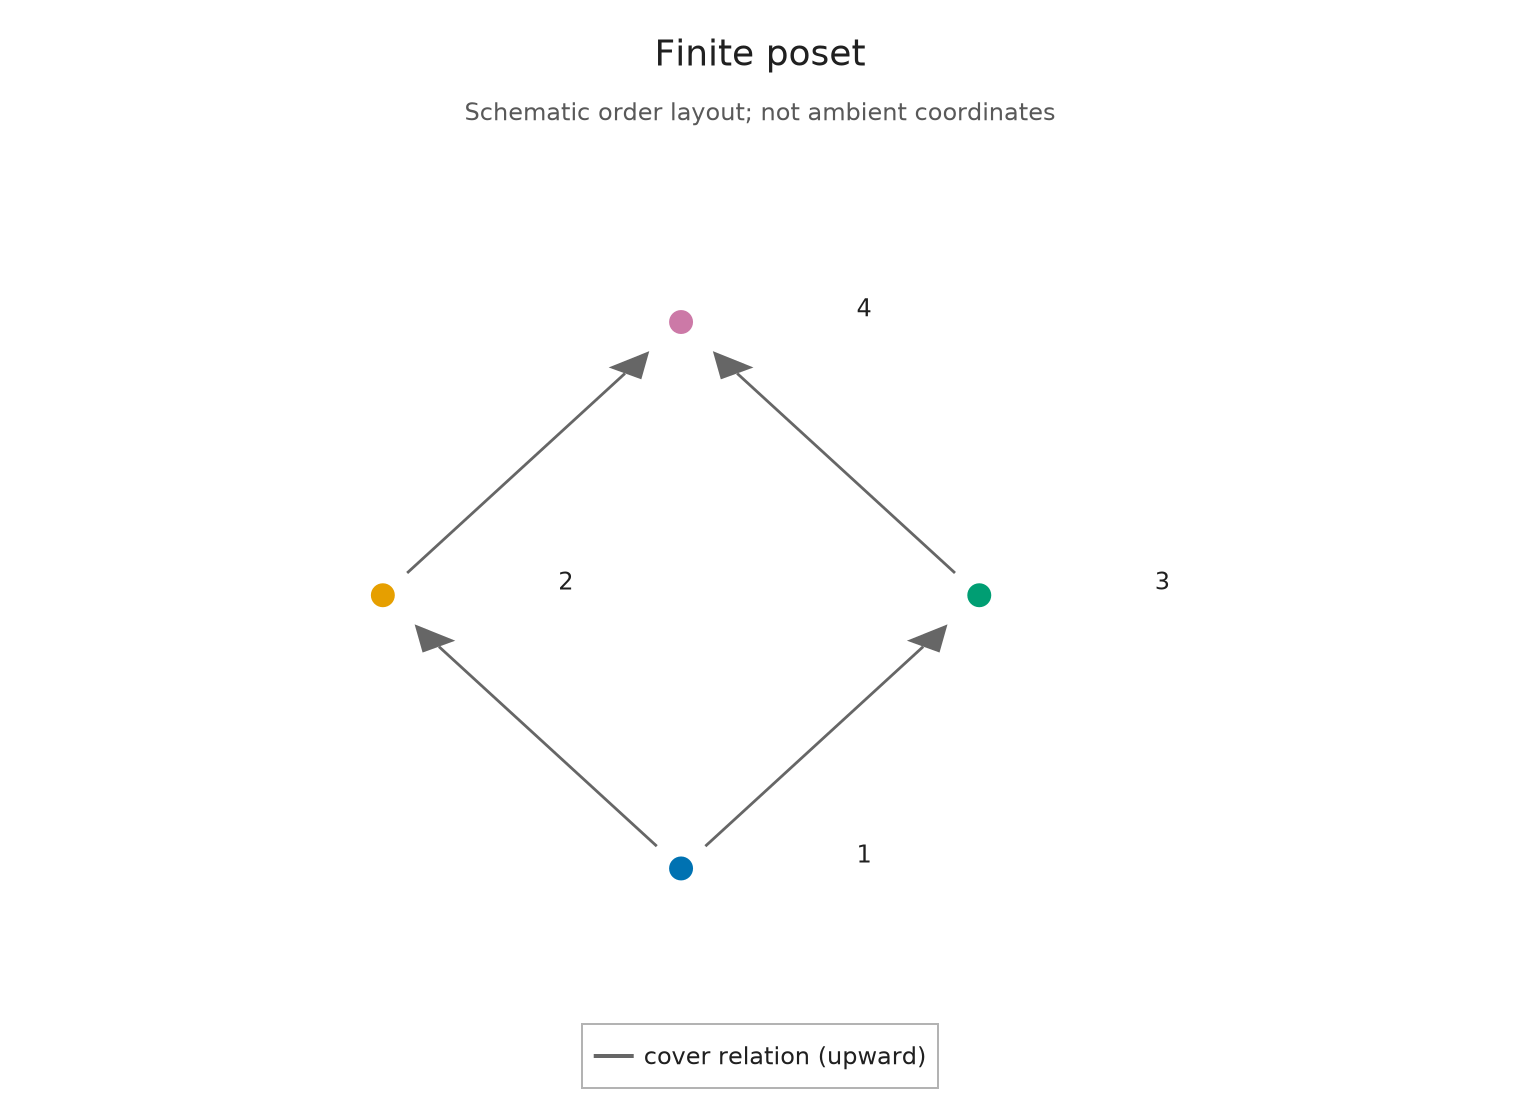

In [1]:
import TamerOp as OP
import CairoMakie
using SparseArrays: sparse

field = OP.CoreModules.QQField()
P = OP.Advanced.FinitePoset(Bool[1 1 1 1; 0 1 0 1; 0 0 1 1; 0 0 0 1])
OP.visualize(P)


## A small category with two routes

Let $S_i$ have one copy of the field at vertex $i$, and zero at the other vertices. All its cover maps are zero. These are the four vertex-simple modules. The word *simple* means that their only submodules are zero and themselves.

For this diamond, there is a nonzero degree-one extension class from $S_1$ to $S_2$, and another from $S_2$ to $S_4$. There is also a one-dimensional degree-two group from $S_1$ to $S_4$. We will compose along the first route and compare it with the route through $S_3$. The shapes of zero maps still matter: a map from a one-dimensional space to zero has zero rows and one column.

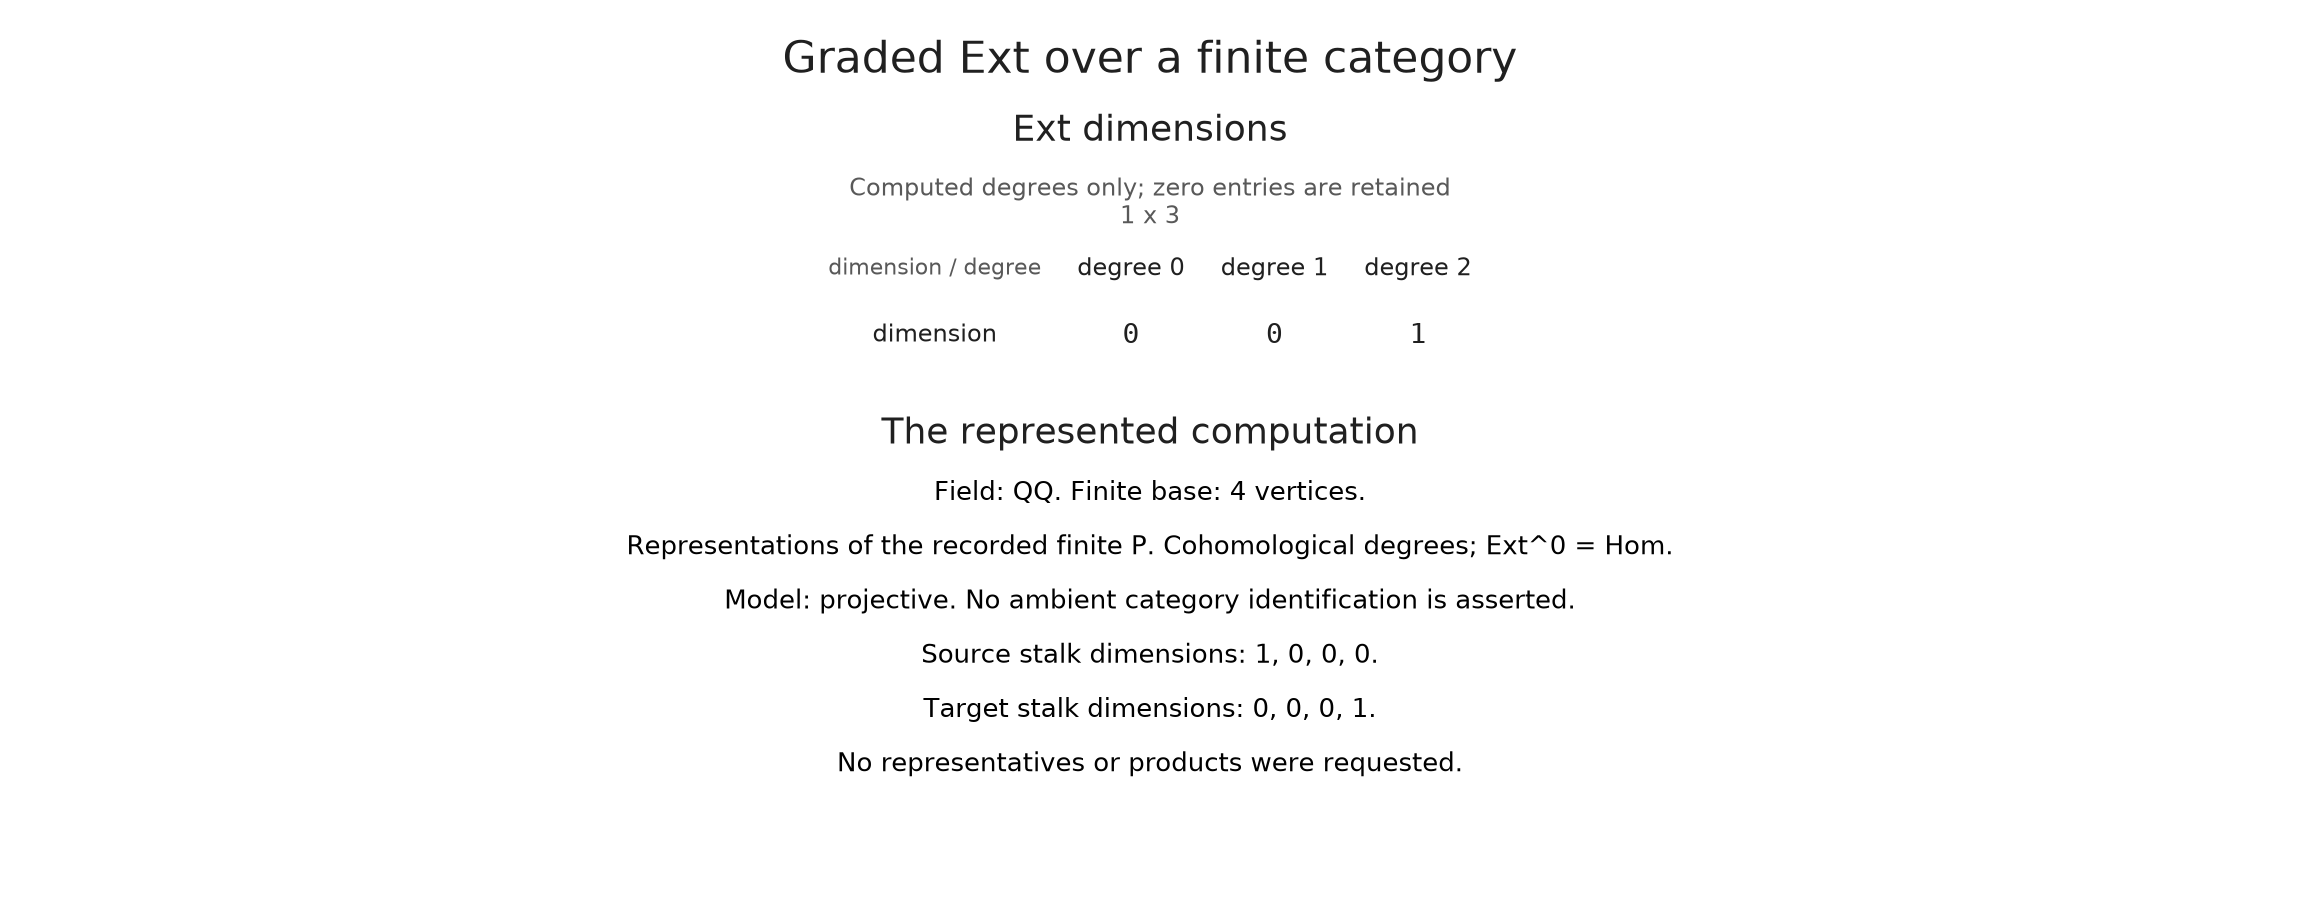

In [2]:
stalks = [[Int(v == i) for v in 1:4] for i in 1:4]
simples = [OP.Advanced.PModule{OP.QQ}(P, dims,
    Dict((u,v) => zeros(OP.QQ, dims[v], dims[u]) for (u,v) in OP.Advanced.cover_edges(P)); field)
    for dims in stalks]
S1, S2, S3, S4 = simples
E14 = OP.ext(S1, S4; maxdeg=2)
OP.visualize(E14)


The table records degrees 0 through 2. A zero says the computed group is zero; an omitted degree says nothing. In degree zero, Ext is ordinary Hom. We have counted classes without asking for representative vectors or products.

Use `cache=sc`, with `sc = OP.SessionCache()`, when repeated requests should reuse compatible resolutions. The cache is a computation choice; it does not change the finite category or identify unrelated coordinate bases.

In [3]:
OP.describe(E14)


(kind = :ext_space, model = :projective, provenance = (category = :finite_poset_representations, base_poset = FinitePoset(nvertices=4), field = TamerOp.CoreModules.CoeffFields.QQField(), degree = 0:2, degree_convention = :cohomological, model = :projective, orientation = :forward, argument_variance = (:contravariant, :covariant), ambient_identification = :not_asserted), field = TamerOp.CoreModules.CoeffFields.QQField(), nvertices = 4, degree_range = 0:2, nonzero_degrees = (2,), degree_dimensions = Dict(2 => 1), total_dimension = 1)

## From a class to a representative

An Ext class is a cocycle modulo coboundaries. A *cocycle* is a vector killed by the next differential; a *coboundary* is in the image of the previous differential. Different cocycles can therefore represent the same class.

`vector=[1]` specifies one coordinate in the chosen basis of the one-dimensional Ext group. It is not an ambient stalk vector. The figure shows its representative together with the incoming and outgoing differentials.

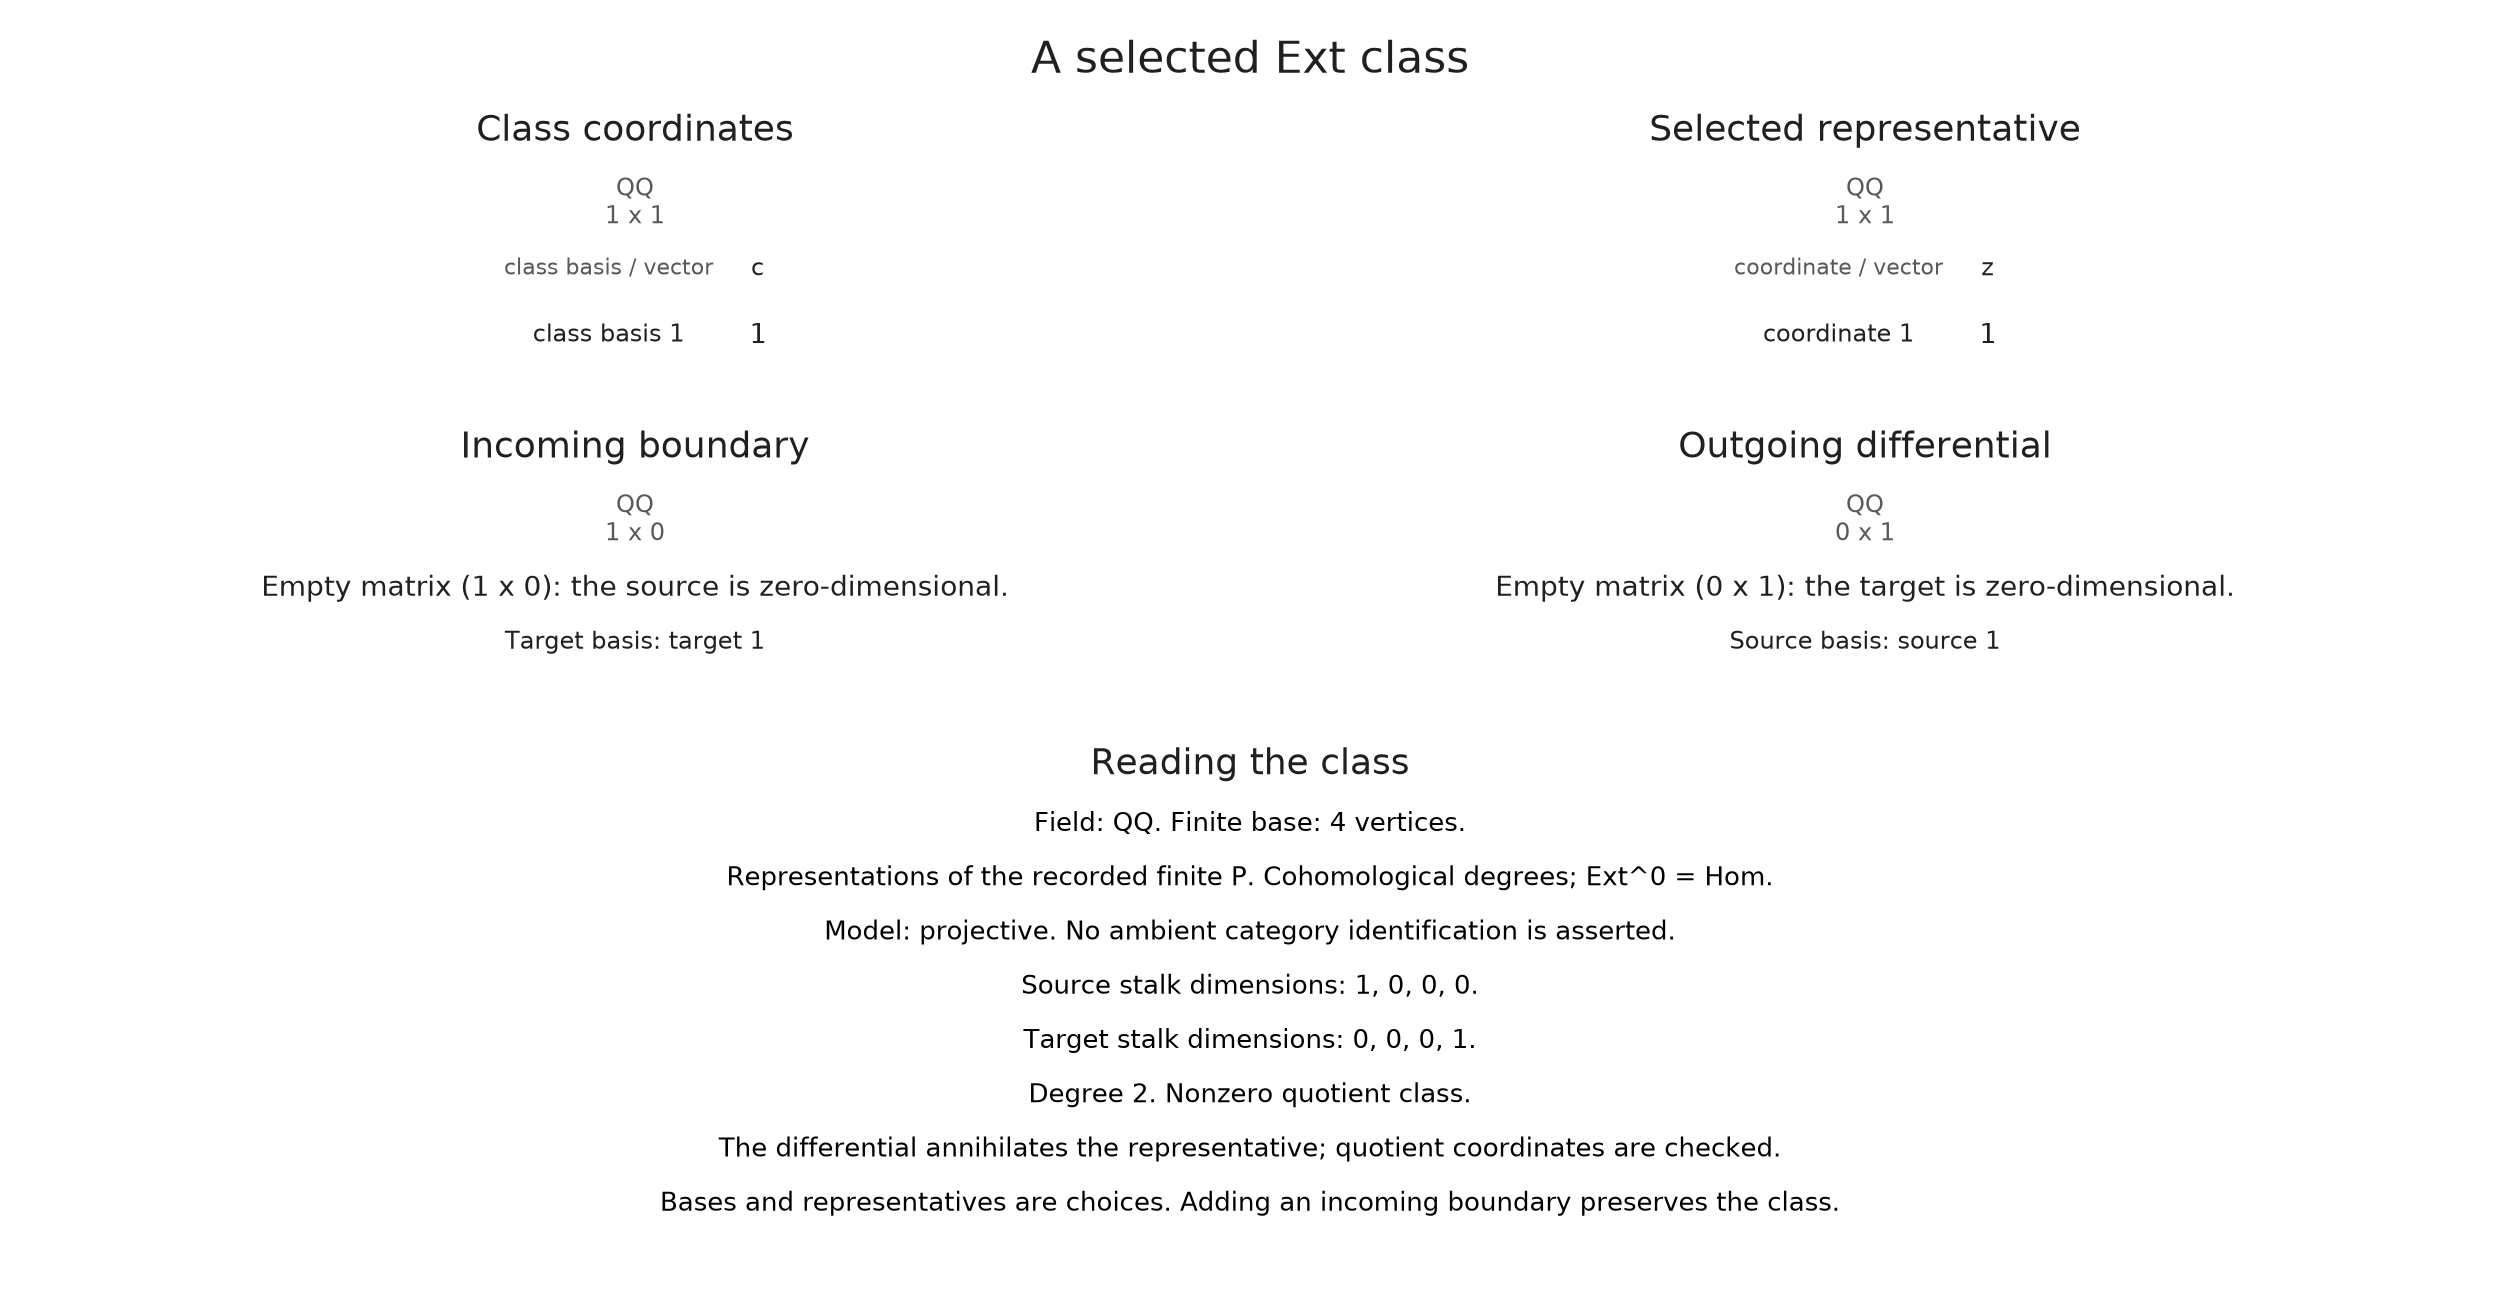

In [4]:
OP.visualize(E14; kind=:derived_class, degree=2, vector=[1])


The renderer does not decide whether a vector is a class. The specification is prepared from the actual complex and verifies the cycle and quotient-coordinate equations before plotting. Exact coefficients remain in its metadata.

In [5]:
class_view = OP.Advanced.visual_spec(E14; kind=:derived_class, degree=2, vector=[1])
selection = class_view.metadata.selection
@assert selection.cycle_equation.valid
@assert selection.coordinate_equation.valid
selection.coordinates


1-element Vector{Rational{BigInt}}:
 1

## Compose along the two routes

Write $\alpha\in\operatorname{Ext}^1(S_1,S_2)$ and $\beta\in\operatorname{Ext}^1(S_2,S_4)$. The Yoneda product $\beta\alpha$ belongs to $\operatorname{Ext}^2(S_1,S_4)$. The left factor acts after the right factor, just as in matrix composition.

The right-hand resolution must reach the sum of the two degrees. We therefore retain it through degree 2. Supplying `target=E14` fixes the coordinates in which both routes will be compared. The figure presents computed cocycles; it does not invent a sequence of extension modules.

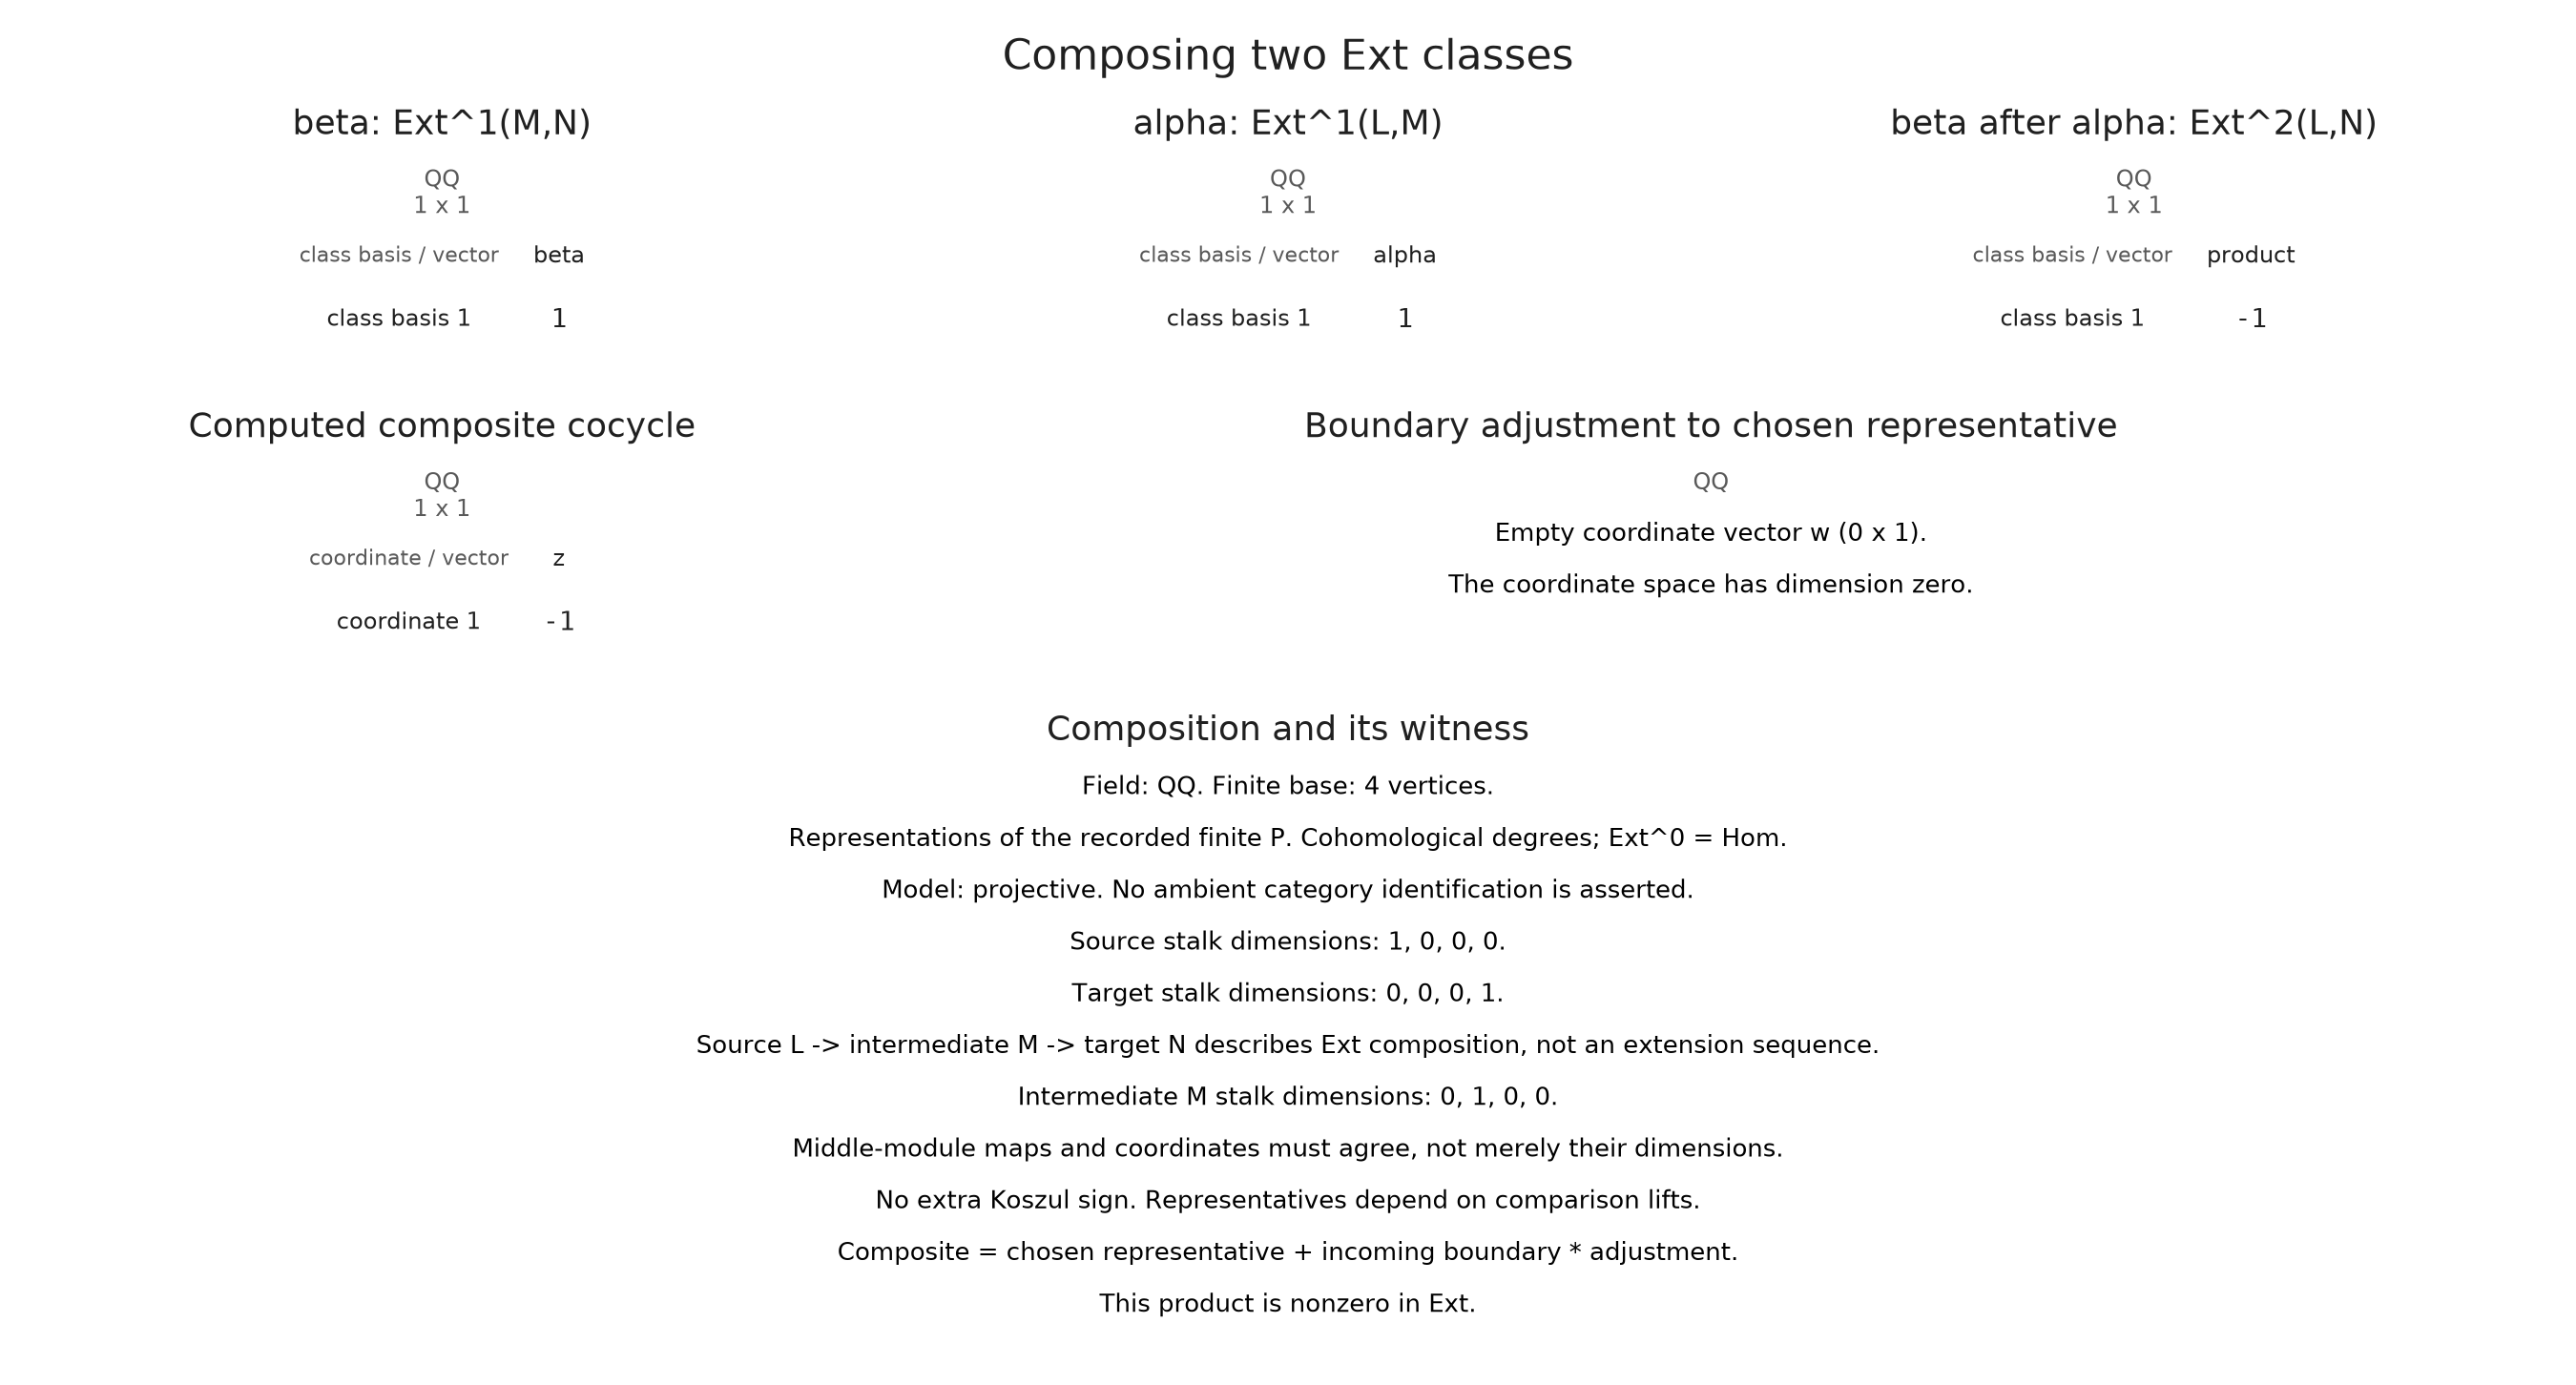

In [6]:
E24 = OP.ext(S2, S4; maxdeg=1)
E12 = OP.ext(S1, S2; maxdeg=2)
via2 = OP.Advanced.visual_spec(E24; kind=:yoneda_product,
    right=E12, p=1, q=1, left_vector=[1], right_vector=[1], target=E14)
OP.visualize(via2)


In [7]:
E34 = OP.ext(S3, S4; maxdeg=1)
E13 = OP.ext(S1, S3; maxdeg=2)
via3 = OP.Advanced.visual_spec(E34; kind=:yoneda_product,
    right=E13, p=1, q=1, left_vector=[1], right_vector=[1], target=E14)
c2 = via2.metadata.selection.coordinates
c3 = via3.metadata.selection.coordinates
@assert c2 != [0]
@assert c2 == -c3
(c2, c3)


(Rational{BigInt}[-1], Rational{BigInt}[1])

The two products are nonzero and have opposite coordinates in the same target basis. This is the signed relation dual to the diamond's commutative square. No extra sign is manually inserted into the multiplication call. In characteristic two, opposite coefficients agree; changing the field changes how the relation is written.

As an exercise, replace the left coordinates by `[0]`. The product must be zero. The following call checks that prediction.

In [8]:
zero_product = OP.Advanced.visual_spec(E24; kind=:yoneda_product,
    right=E12, p=1, q=1, left_vector=[0], right_vector=[1], target=E14)
@assert zero_product.metadata.selection.zero_class
zero_product.metadata.selection.coordinates


1-element Vector{Rational{BigInt}}:
 0

## Compute a whole degree pair when it is useful

Put the four simple modules together. At every vertex the resulting module has a one-dimensional stalk, but every cover map is zero. It differs from a constant module, whose cover maps are identities. Its self-Ext dimensions are 4, 4, and 1.

An `ExtAlgebra` retains one resolution and caches completed multiplication tables. Requesting the algebra's default view still reads only dimensions. An explicit `:product_table` request computes one degree pair. Columns are ordered pairs of input basis vectors, with the right index changing fastest; rows are target coordinates.

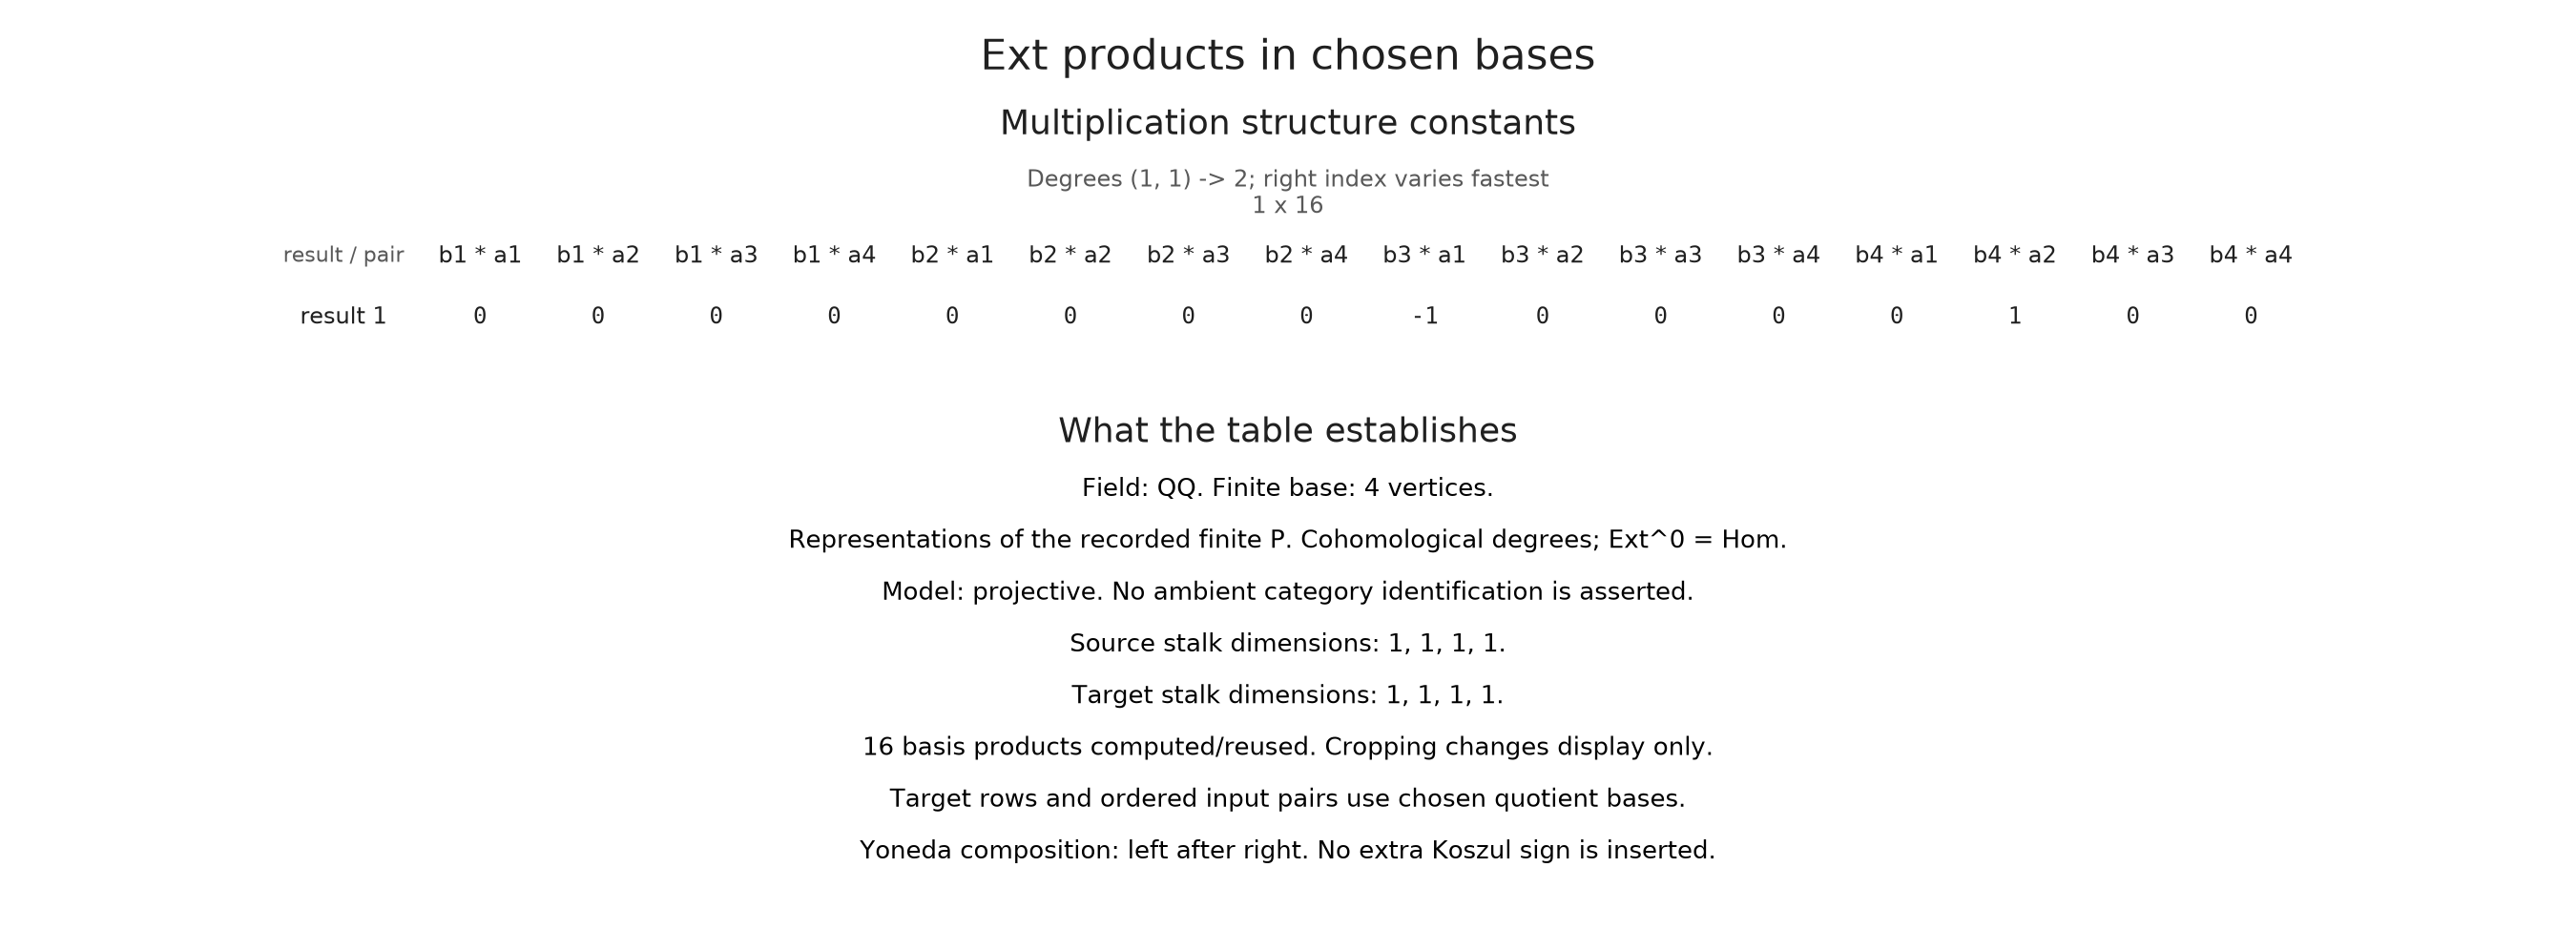

In [9]:
M = OP.Advanced.PModule{OP.QQ}(P, ones(Int,4),
    Dict(edge => zeros(OP.QQ,1,1) for edge in OP.Advanced.cover_edges(P)); field)
finite = OP.EncodingResult(P, M, nothing)
A = OP.ext_algebra(finite; maxdeg=2)
OP.visualize(A; kind=:product_table, p=1, q=1, matrix_limit=(1,16))


There are sixteen possible basis products, only two of which are nonzero. The default table budget is 4096 input pairs and one million output coefficients. Raising `max_products` or `max_entries` permits more computation. Raising `matrix_limit` only displays more of the already computed matrix.

In [10]:
constants = OP.Advanced.multiplication_matrix(A, 1, 1)
@assert size(constants) == (1,16)
@assert count(!iszero, constants) == 2
@assert sum(constants) == 0
OP.Advanced.cached_product_degrees(A)


1-element Vector{Tuple{Int64, Int64}}:
 (1, 1)

## Induced maps use declared coordinates

Ext is contravariant in its first module and covariant in its second. Here an endomorphism multiplying $S_1$ by 2 induces multiplication by 2 on $\operatorname{Ext}^2(S_1,S_4)$. For a general morphism the source and destination Ext models must match the operation's variance; equal dimensions are not enough.

In [11]:
twice = OP.Advanced.PMorphism(S1, S1,
    [2 * ones(OP.QQ,d,d) for d in stalks[1]])
induced = OP.Advanced.ext_map_first(E14, E14, twice; t=2)
@assert induced == reshape(OP.QQ[2],1,1)
induced


1×1 Matrix{Rational{BigInt}}:
 2

## Tor pairs opposite actions

Incidence-algebra Tor pairs a right module, represented on $P^{op}$, with a left module on $P$. This is distinct from the pointwise tensor of two forward modules. On a two-vertex chain, take the right simple at the top and the left simple at the bottom. Their Tor is zero in degree 0 and one-dimensional in degree 1.

Tor degrees are homological: the boundary lowers degree. The representative view keeps these labels even though the shared complex inspector uses the equivalent indexing $C^{-s}=C_s$.

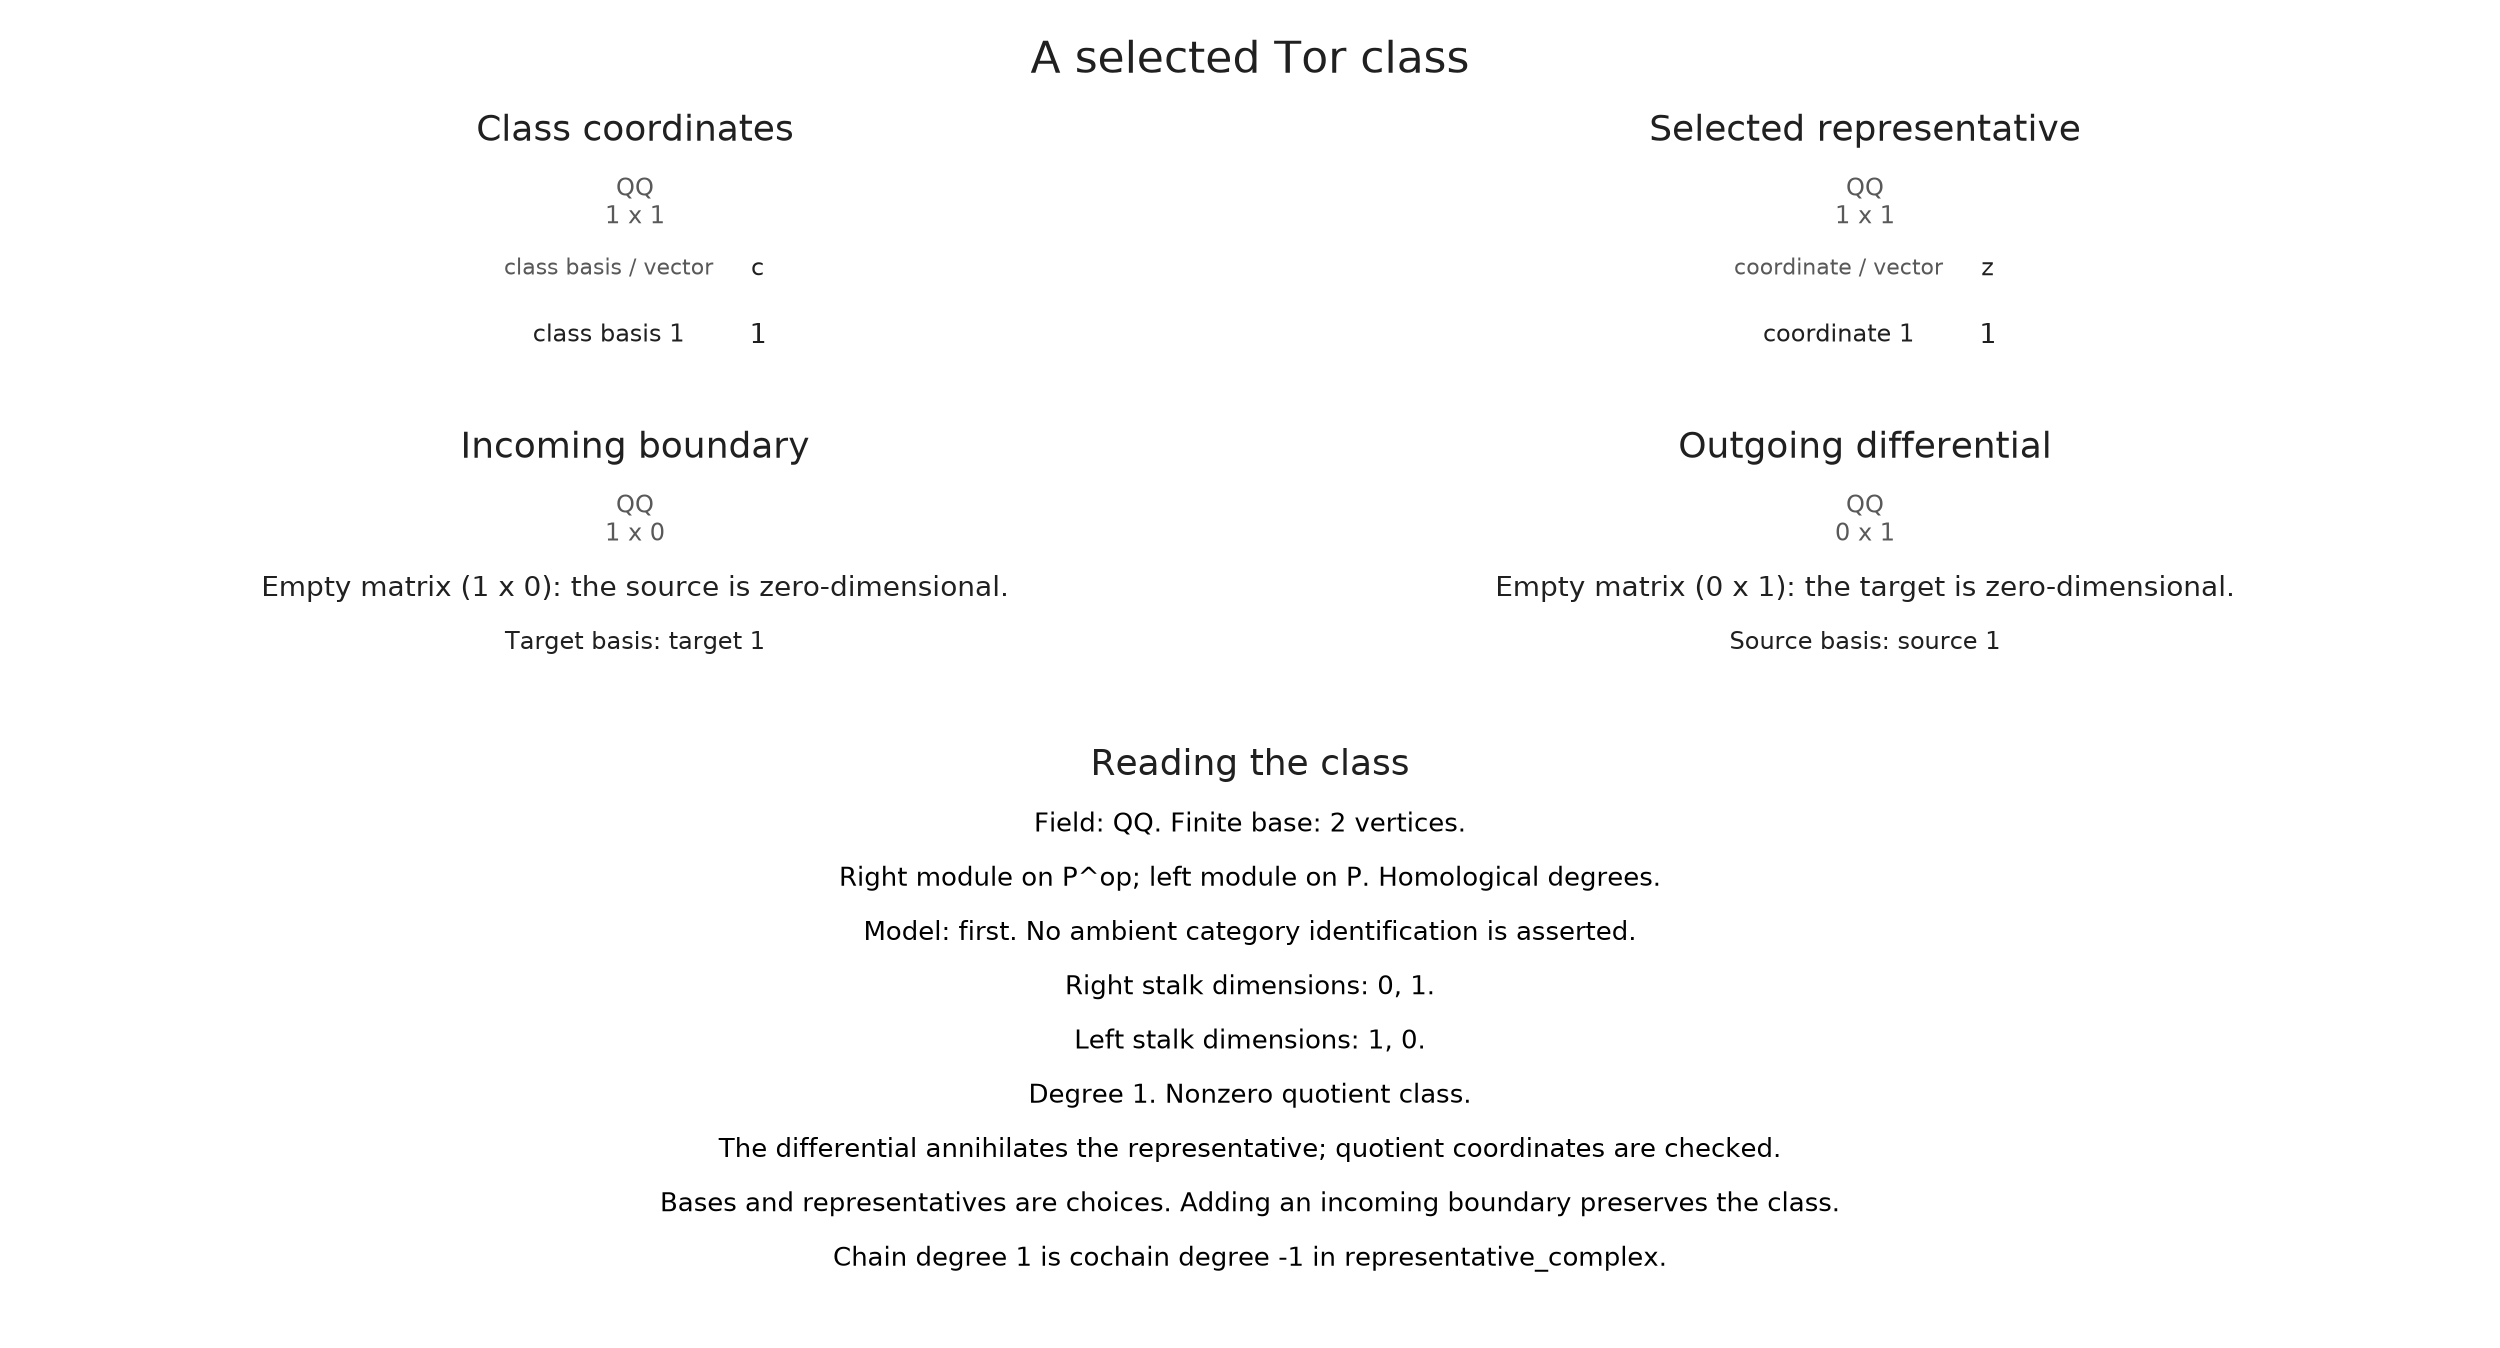

In [12]:
Q = OP.Advanced.FinitePoset(Bool[1 1;0 1])
Qop = OP.Advanced.FinitePoset(Bool[1 0;1 1])
R = OP.Advanced.PModule{OP.QQ}(Qop, [0,1], Dict((2,1)=>zeros(OP.QQ,0,1)); field)
L = OP.Advanced.PModule{OP.QQ}(Q, [1,0], Dict((1,2)=>zeros(OP.QQ,0,1)); field)
T = OP.tor(R,L; maxdeg=1)
@assert [OP.Advanced.dim(T,s) for s in 0:1] == [0,1]
OP.visualize(T; kind=:derived_class, degree=1, vector=[1])


### Multiplication is additional input

Two modules do not, by themselves, define a Tor algebra. To demonstrate the contract, use the category with one vertex and take both modules to be the field. The tensor complex is the field in degree zero. We explicitly supply ordinary scalar multiplication, whose matrix is `[1]` in the chosen bases.

`TorAlgebra` is an advanced constructor because specifying chain products is a mathematical responsibility. `validate_algebra=true` checks the Leibniz identity, homology associativity, and a supplied unit throughout the computed range. Without this option, each requested product still checks preservation of cycles and independence modulo boundaries.

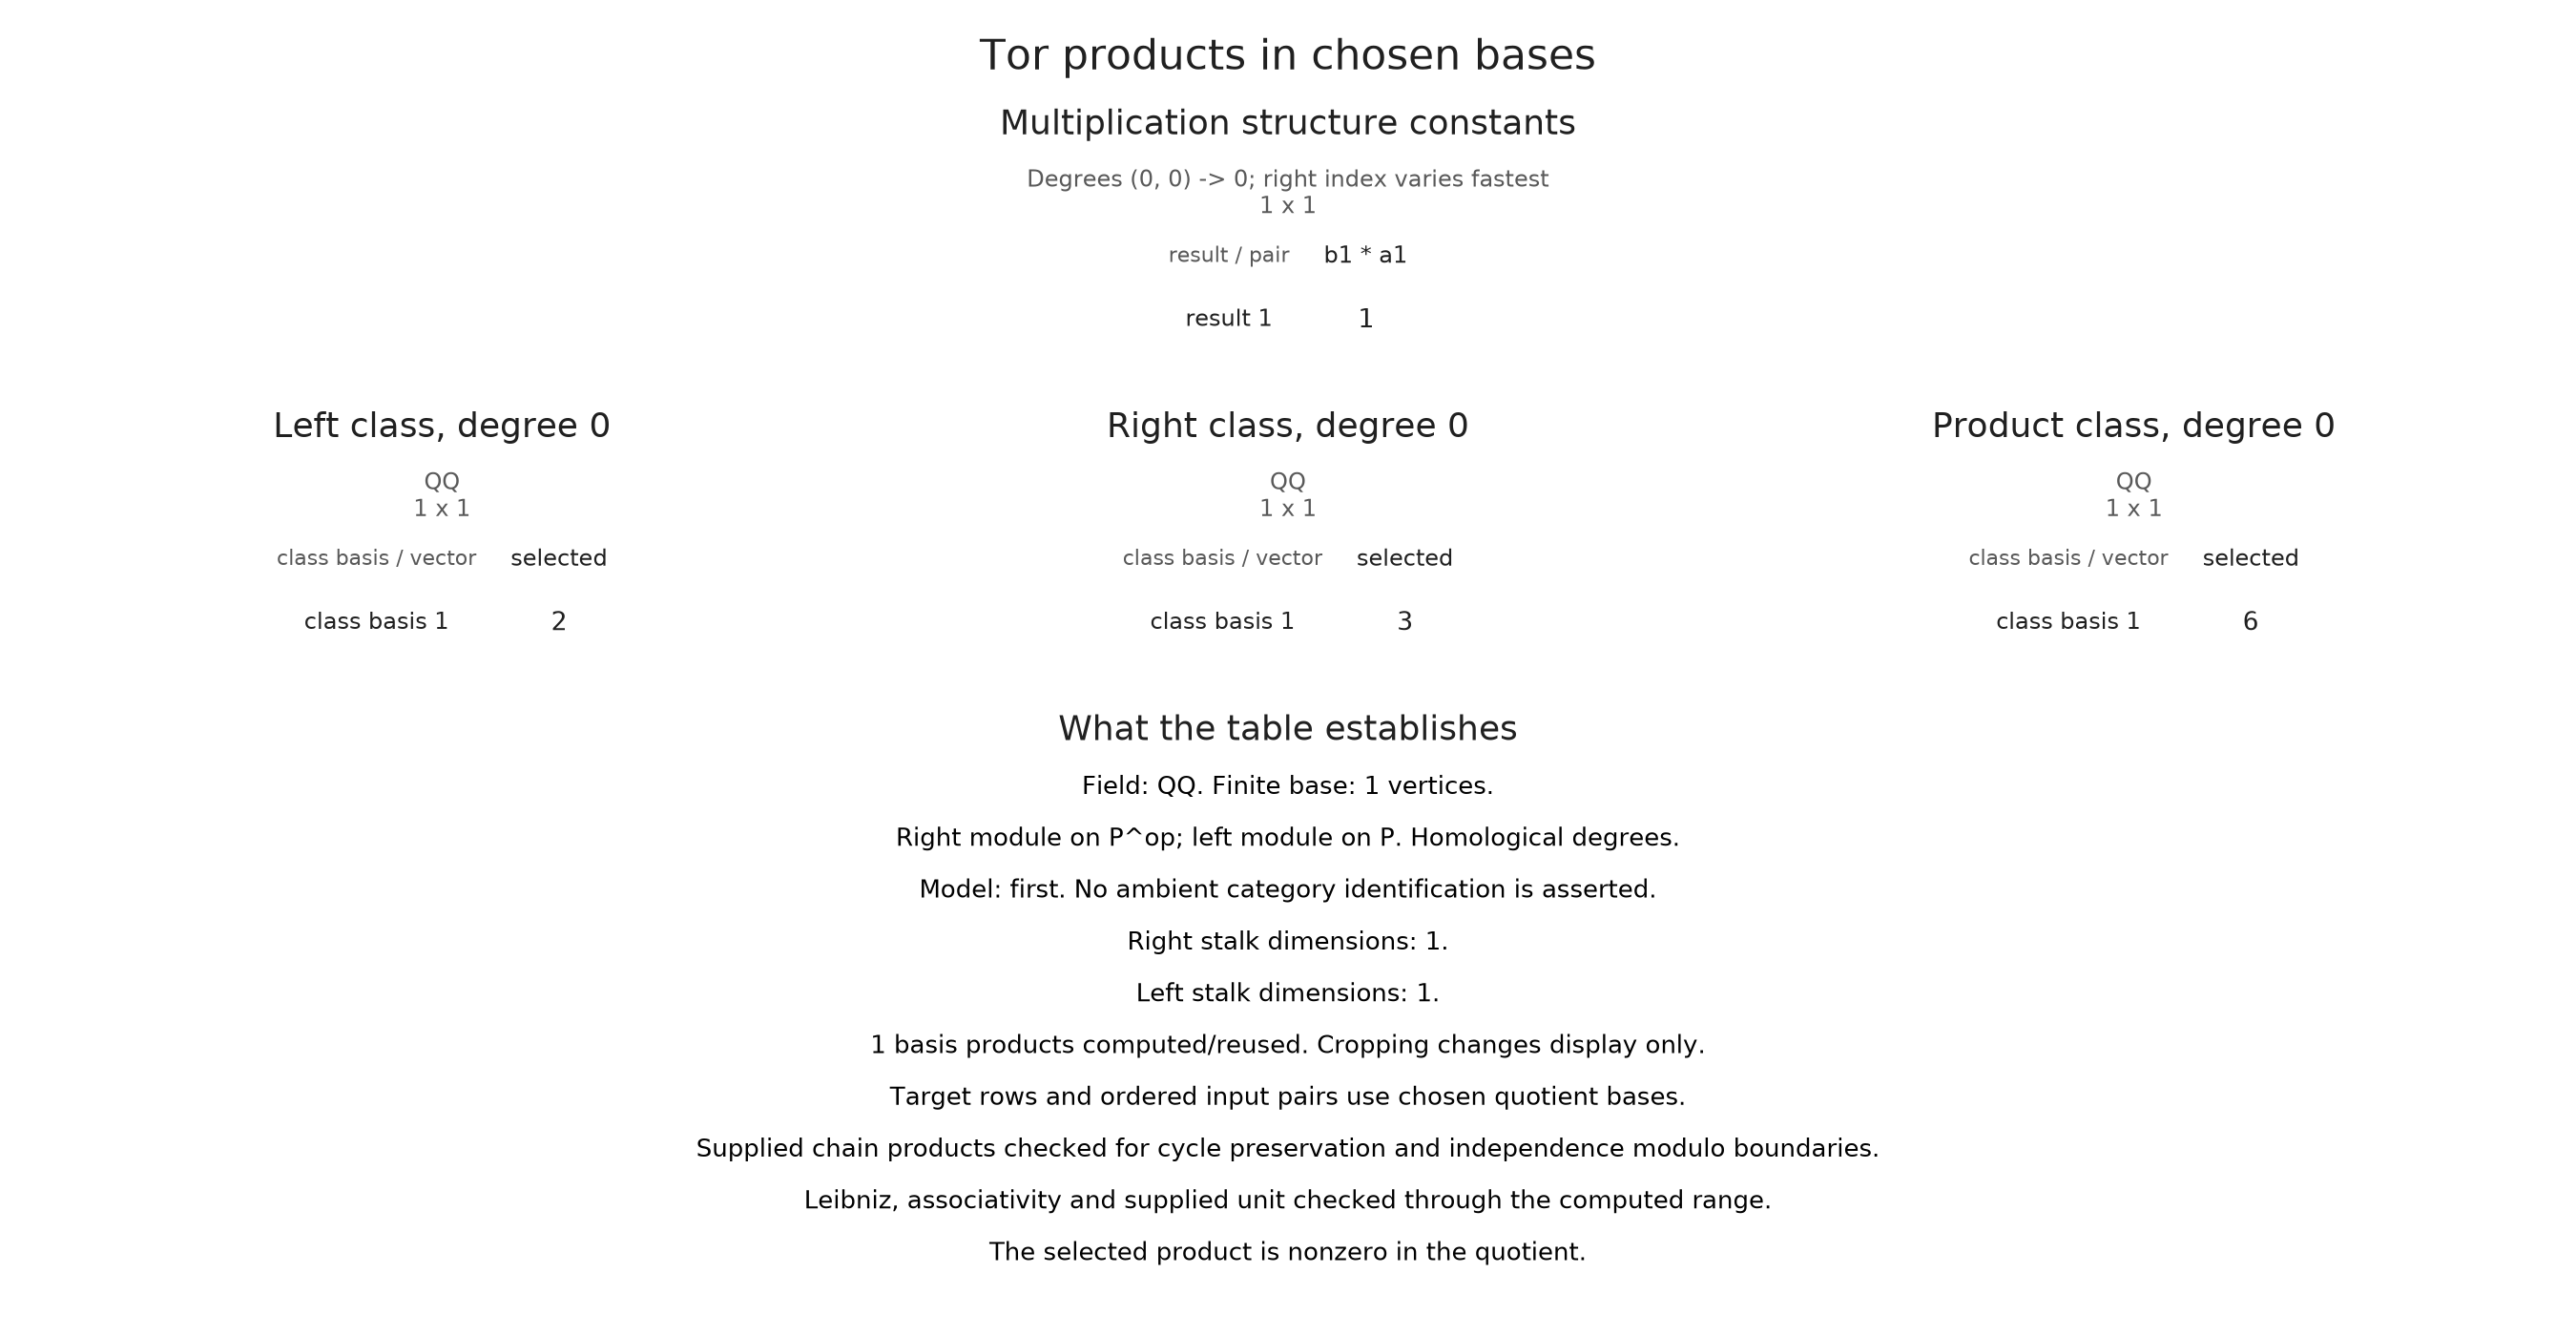

In [13]:
point = OP.Advanced.FinitePoset(trues(1,1))
Kpoint = OP.Advanced.PModule{OP.QQ}(point, [1], Dict{Tuple{Int,Int},Matrix{OP.QQ}}(); field)
Tpoint = OP.tor(Kpoint,Kpoint; maxdeg=0)
scalar_algebra = OP.Advanced.TorAlgebra(Tpoint;
    mu_chain=Dict((0,0)=>sparse(reshape(OP.QQ[1],1,1))), unit_coords=OP.QQ[1])
OP.visualize(scalar_algebra; kind=:product_table, left=[2], right=[3], validate_algebra=true)


## Optional: export the selected computation

The same prepared specification can be exported without repeating the product calculation. PNG, SVG and PDF preserve matrix labels, crops and explanatory text. The specification is a static view; exporting it does not create a live algebra session.

In [14]:
export_directory = mktempdir()
OP.save_visual(joinpath(export_directory,"yoneda.svg"), via2)
export_directory


"/tmp/jl_0LWnQZ"

We counted derived groups, selected quotient representatives, composed two nonzero classes, and distinguished Tor homology from the extra structure of a Tor product. The [reference](../src/reference/derived.md) gives exact request contracts and the [implementation account](../implementation/yoneda_products.md) follows the comparison lifts and quotient checks. To explore how a chosen class is represented by cycles and boundaries, continue with the [complex guide](complexes.ipynb).